# Task 1 · MLP vs CNN
Every run trains on 4 folds of the training set (40,000 images) and validates on the 5th (10,000).
Numbers are mean (SD) over the 5 folds; runs are cached in `out/runs`.

In [1]:
from hw3 import *

X, Y, Xte, Yte = cifar()
X.shape, Xte.shape, [len(f) for f in folds()], Y[folds()[0]].bincount().tolist()

(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 [10000, 10000, 10000, 10000, 10000],
 [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000])

## Hyperparameter search

In [2]:
LRS = {'mlp': (3e-4, 1e-3, 3e-3), 'cnn': (1e-3, 3e-3, 1e-2)}
SIZES = {'mlp': [(512, 256), (1024, 512, 256)], 'cnn': [16, 32]}
widths = lambda m, s: '-'.join(map(str, s if m == 'mlp' else (s, 2 * s, 4 * s)))
cfgs = {f'{m}_{widths(m, s)}_{lr:g}': dict(model=partial(MLP if m == 'mlp' else CNN, s), lr=lr)
        for m in SIZES for s in SIZES[m] for lr in LRS[m]}
R = cv(cfgs)

In [3]:
hp = pd.DataFrame([k.split('_') + [f"{R[k][0]['params'] / 1e6:.2f}", last(R[k], 'val_acc').mean(),
                                   ms(last(R[k], 'val_acc')), ms(last(R[k], 'val_loss'), 1, 3),
                                   ms([r['time'].mean() for r in R[k]], 1, 0)] for k in R], index=list(R),
                  columns=['model', 'widths', 'peak lr', 'params (M)', 'acc', 'val acc', 'val loss', 's/epoch (1 thread)'])
best = hp.groupby('model', sort=False).acc.idxmax()
with open(BEST, 'w') as f:
    json.dump({m: dict(key=k, arch=cfgs[k]['model'].args[0], lr=cfgs[k]['lr']) for m, k in best.items()}, f)
rows('hp', hp.drop(columns='acc').assign(model=hp.model.str.upper()).set_index('model'))
hp.drop(columns='acc')

,model,widths,peak lr,params (M),val acc,val loss,s/epoch (1 thread)
mlp_512-256_0.0003,mlp,512-256,0.0003,1.71,55.6 (0.5),1.305 (0.017),23 (0)
mlp_512-256_0.001,mlp,512-256,0.001,1.71,56.1 (0.6),1.381 (0.017),22 (2)
mlp_512-256_0.003,mlp,512-256,0.003,1.71,54.1 (0.3),1.444 (0.025),23 (2)
mlp_1024-512-256_0.0003,mlp,1024-512-256,0.0003,3.81,56.7 (0.4),1.340 (0.027),65 (3)
mlp_1024-512-256_0.001,mlp,1024-512-256,0.001,3.81,56.5 (0.5),1.534 (0.031),51 (7)
mlp_1024-512-256_0.003,mlp,1024-512-256,0.003,3.81,54.8 (0.5),1.485 (0.019),44 (0)
cnn_16-32-64_0.001,cnn,16-32-64,0.001,0.29,76.3 (0.5),0.702 (0.011),55 (3)
cnn_16-32-64_0.003,cnn,16-32-64,0.003,0.29,78.3 (0.4),0.702 (0.013),54 (1)
cnn_16-32-64_0.01,cnn,16-32-64,0.01,0.29,78.1 (0.5),0.844 (0.021),60 (5)
cnn_32-64-128_0.001,cnn,32-64-128,0.001,0.62,79.9 (0.4),0.630 (0.012),115 (6)


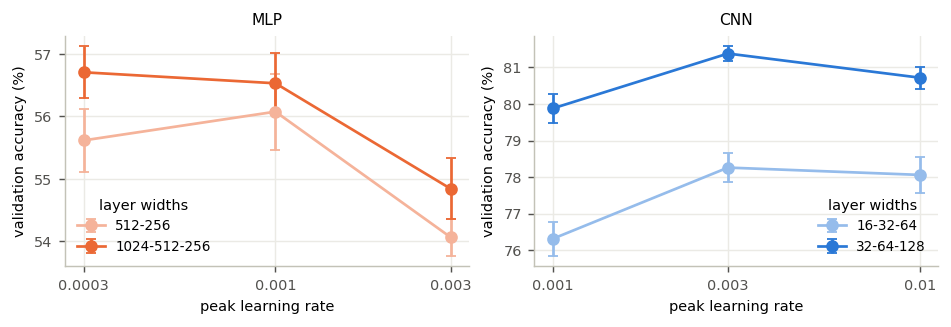

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4))
for ax, m in zip(axes, SIZES):
    for s, a in zip(SIZES[m], (.5, 0)):
        v = np.array([last(R[f'{m}_{widths(m, s)}_{lr:g}'], 'val_acc') for lr in LRS[m]]) * 100
        ax.errorbar(LRS[m], v.mean(1), v.std(1, ddof=1), marker='o', capsize=3, color=mix(COL[m], 'white', a), label=widths(m, s))
    ax.set(xscale='log', xlabel='peak learning rate', ylabel='validation accuracy (%)', title=m.upper())
    ax.set_xticks(LRS[m], [f'{lr:g}' for lr in LRS[m]])
    ax.minorticks_off()
    ax.legend(title='layer widths')
save(fig, 'hp')

## Selected architectures

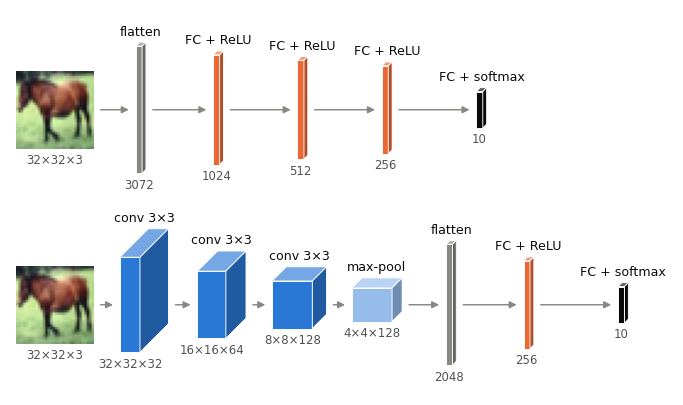

In [5]:
i = int((Y == 7).nonzero()[0])
mlp, cnn = (cfgs[best[m]]['model'].args[0] for m in ('mlp', 'cnn'))
diagram('arch', [[(3072, 'flatten', MUTED)] + [(h, 'FC + ReLU', COL['mlp']) for h in mlp] + [(10, 'FC + softmax', INK)],
                 cnn_layers(cnn)], X[i])

## Accuracy, size, speed and memory

In [6]:
P = pd.DataFrame({m: profile(cfgs[k]['model']) for m, k in best.items()}).T
P['val'], P['test'] = ([ms(last(R[k], key)) for k in best] for key in ('val_acc', 'test_acc'))
P

,params,mflops,weights,adam,acts,epoch,val,test
mlp,3805450.0,7.607296,14.516640,43.549919,2.375000,9.905781,56.7 (0.4),56.4 (0.3)
cnn,620810.0,21.697536,2.368202,7.104607,78.628418,30.425000,81.4 (0.2),81.0 (0.3)


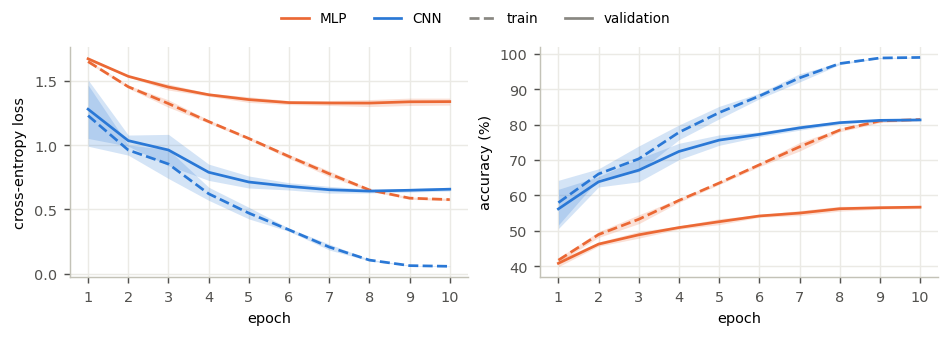

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
curves({m.upper(): (R[k], COL[m]) for m, k in best.items()}, axes)
save(fig, 'curves')

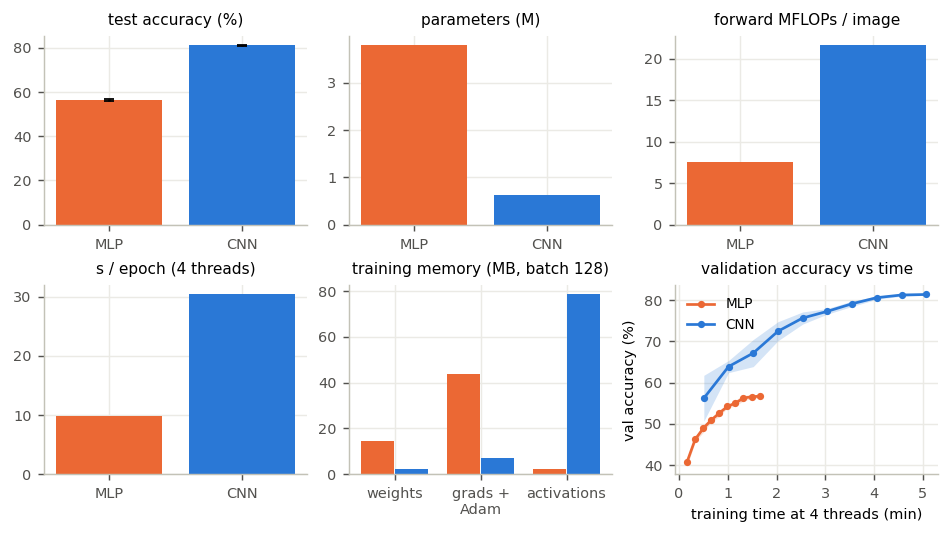

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(7.2, 4))
names, colors = [m.upper() for m in best.index], [COL[m] for m in best.index]
acc = np.array([last(R[k], 'test_acc') for k in best]) * 100
axes[0, 0].bar(names, acc.mean(1), yerr=acc.std(1, ddof=1), capsize=3, color=colors)
for ax, key, k in zip(axes.flat[1:4], ('params', 'mflops', 'epoch'), (1e6, 1, 1)):
    ax.bar(names, P[key] / k, color=colors)
for j, m in enumerate(best.index):
    axes[1, 1].bar(np.arange(3) + .4 * j - .2, P.loc[m, ['weights', 'adam', 'acts']].astype(float), .38, color=COL[m])
    v = np.stack([np.asarray(r['val_acc']) for r in R[best[m]]]) * 100
    t, s = P.epoch[m] / 60 * np.arange(1, v.shape[1] + 1), v.std(0, ddof=1)
    axes[1, 2].fill_between(t, v.mean(0) - s, v.mean(0) + s, color=COL[m], alpha=.2, lw=0)
    axes[1, 2].plot(t, v.mean(0), 'o-', ms=3, color=COL[m], label=m.upper())
axes[1, 1].set_xticks(range(3), ['weights', 'grads +\nAdam', 'activations'])
axes[1, 2].set(xlabel='training time at 4 threads (min)', ylabel='val accuracy (%)')
axes[1, 2].legend()
for ax, t in zip(axes.flat, ('test accuracy (%)', 'parameters (M)', 'forward MFLOPs / image', 's / epoch (4 threads)',
                             'training memory (MB, batch 128)', 'validation accuracy vs time')):
    ax.set_title(t)
save(fig, 'compare')

## What the weights look like

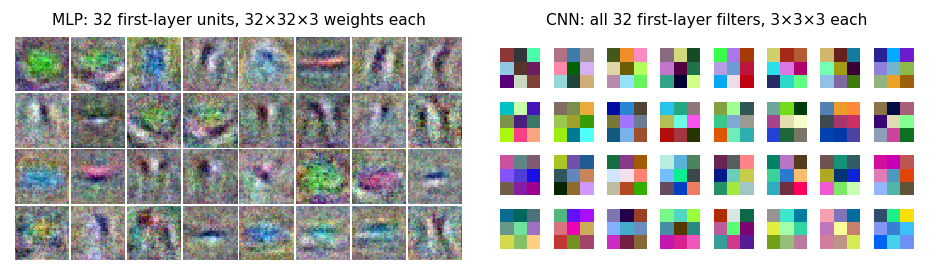

In [9]:
mlp, cnn = (load(best[m], cfgs[best[m]]['model']) for m in ('mlp', 'cnn'))
W = mlp[1].weight.detach()
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2))
tiles(axes[0], W[W.norm(dim=1).argsort(descending=True)[:32]].view(-1, 3, 32, 32))
tiles(axes[1], cnn[0][0].weight.detach())
axes[0].set_title('MLP: 32 first-layer units, 32×32×3 weights each')
axes[1].set_title(f'CNN: all {len(cnn[0][0].weight)} first-layer filters, 3×3×3 each')
save(fig, 'weights')

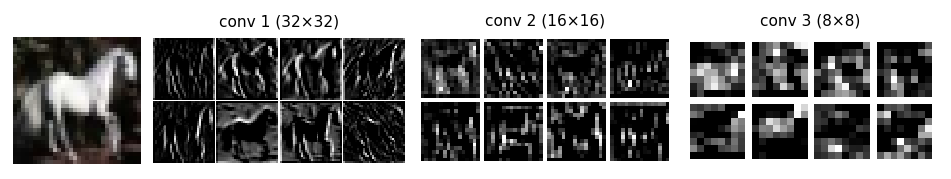

In [10]:
j = int((Yte == 7).nonzero()[0])
x, maps = prep(Xte[j:j + 1]), []
with torch.no_grad():
    for b in cnn[:3]:
        a = b[:3](x)[0]
        maps.append(a[a.mean((1, 2)).argsort(descending=True)[:8], None])
        x = b(x)
fig, axes = plt.subplots(1, 4, figsize=(7.2, 1.6), gridspec_kw=dict(width_ratios=[1, 2, 2, 2]))
axes[0].imshow(Xte[j].permute(1, 2, 0))
axes[0].axis('off')
for r, (ax, a) in enumerate(zip(axes[1:], maps)):
    tiles(ax, a, 4)
    ax.set_title(f'conv {r + 1} ({a.shape[-1]}×{a.shape[-1]})')
save(fig, 'featuremaps')

## Shuffling the pixels
One fixed random permutation of the 1,024 pixel positions, applied to every image: the MLP cannot tell, the CNN loses
the neighbourhoods its 3×3 filters rely on.

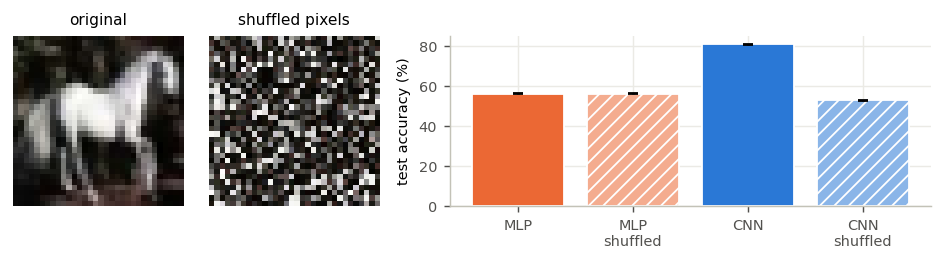

In [11]:
Q = cv({f'{k}_perm': cfgs[k] | dict(kind='perm') for k in best})
x = Xte[j:j + 1]
fig, axes = plt.subplots(1, 3, figsize=(7.2, 1.9), gridspec_kw=dict(width_ratios=[1, 1, 2.6]))
for ax, img, t in zip(axes, (x, x.flatten(2)[..., PERM].view_as(x)), ('original', 'shuffled pixels')):
    ax.imshow(img[0].permute(1, 2, 0))
    ax.set_title(t)
    ax.axis('off')
for q, m in enumerate(best.index):
    for c, runs in enumerate((R[best[m]], Q[f'{best[m]}_perm'])):
        a = last(runs, 'test_acc') * 100
        axes[2].bar(2 * q + c, a.mean(), .8, yerr=a.std(ddof=1), capsize=3, color=mix(COL[m], 'white', .45 * c),
                    hatch='///' * c, edgecolor='white')
axes[2].set_xticks(range(4), [f'{m.upper()}{s}' for m in best.index for s in ('', '\nshuffled')])
axes[2].set_ylabel('test accuracy (%)')
save(fig, 'perm')

In [12]:
tex('t1', cnnMlpDiff=pdiff(R[best.cnn], R[best.mlp]), **{m + n: v for m, k in best.items() for n, v in dict(
    Widths=hp.widths[k], LR=hp['peak lr'][k], Val=P.val[m], Test=P.test[m], Perm=ms(last(Q[f'{k}_perm'], 'test_acc')),
    Params=f'{P.params[m] / 1e6:.2f}', Flops=f'{P.mflops[m]:.1f}', Epoch=f'{P.epoch[m]:.0f}',
    Mem=f"{P.loc[m, ['weights', 'adam', 'acts']].sum():.0f}", Spread=f'{100 * np.ptp(hp.acc[hp.model == m].to_numpy()):.1f}',
    Tune=f"{sum(r['time'].sum().item() for q in R if q.startswith(m) for r in R[q]) / 3600:.1f}").items()})